**1. Read the log and extract the data**

In [7]:
from pathlib import Path
import csv
import json
import re
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

WORK = Path.cwd()
if not (WORK / "local_data/sample").exists():
    WORK = WORK / "data_extraction"

DATA_FOLDER = WORK / "local_data/sample"
LOG_FOLDER = DATA_FOLDER / "att-test"
OUTPUT_FOLDER = WORK / "outputs"

records = []

for log_file in sorted(LOG_FOLDER.glob("S*.txt")):
    if re.fullmatch(r"S[0-9]+", log_file.stem) is None:
        continue

    with log_file.open(encoding="utf-8") as log:
        lines = log.readlines()

    for line in lines:
        if "webfile/practice/" not in line and "webfile/maps/" not in line:
            continue

        ip, date, time, browser, subject_id, map_path, steps, path_text, times_text = line.split()
        moves_taken = [[int(x), int(y)] for x, y in re.findall(r"p\((\d+),(\d+)\)", path_text)]
        decision_times = [int(value) for value in times_text.split(";") if value]

        records.append({
            "map_name": Path(map_path).name,
            "subject_id": subject_id,
            "date_and_time": f"{date} {time}",
            "moves_taken": moves_taken,
            "decision_times": decision_times
        })

print(f"Subjects: {len(set(row['subject_id'] for row in records))}")
print(f"Maze records: {len(records)}")
records[:2]

Subjects: 1
Maze records: 25


[{'map_name': '1pipe.txt',
  'subject_id': 'S4360259',
  'date_and_time': '20/October/2026 06:04:41',
  'moves_taken': [[0, 2],
   [1, 2],
   [2, 2],
   [3, 2],
   [4, 2],
   [5, 2],
   [6, 2],
   [7, 2],
   [7, 3]],
  'decision_times': [1055, 186, 180, 186, 307, 192, 501, 253]},
 {'map_name': '2tunnel.txt',
  'subject_id': 'S4360259',
  'date_and_time': '20/October/2026 06:04:43',
  'moves_taken': [[0, 0], [1, 0], [2, 0], [2, 1], [2, 2]],
  'decision_times': [998, 156, 371, 358]}]

**2. Save and read the CSV**

In [8]:
OUTPUT_FOLDER.mkdir(exist_ok=True)
CSV_FILE = OUTPUT_FOLDER / "subject_data.csv"
columns = ["map_name", "subject_id", "date_and_time", "moves_taken", "decision_times"]

with CSV_FILE.open("w", encoding="utf-8", newline="") as file:
    writer = csv.DictWriter(file, fieldnames=columns)
    writer.writeheader()
    for record in records:
        writer.writerow({
            "map_name": record["map_name"],
            "subject_id": record["subject_id"],
            "date_and_time": record["date_and_time"],
            "moves_taken": json.dumps(record["moves_taken"]),
            "decision_times": json.dumps(record["decision_times"])
        })

with CSV_FILE.open(encoding="utf-8", newline="") as file:
    subject_data = list(csv.DictReader(file))

print(f"Saved {len(subject_data)} rows to {CSV_FILE}")
subject_data[:3]

Saved 25 rows to /Users/tim/X/DALHOUSIE/CSCI 4192/MST-Keyboard-Experiment/data_extraction/outputs/subject_data.csv


[{'map_name': '1pipe.txt',
  'subject_id': 'S4360259',
  'date_and_time': '20/October/2026 06:04:41',
  'moves_taken': '[[0, 2], [1, 2], [2, 2], [3, 2], [4, 2], [5, 2], [6, 2], [7, 2], [7, 3]]',
  'decision_times': '[1055, 186, 180, 186, 307, 192, 501, 253]'},
 {'map_name': '2tunnel.txt',
  'subject_id': 'S4360259',
  'date_and_time': '20/October/2026 06:04:43',
  'moves_taken': '[[0, 0], [1, 0], [2, 0], [2, 1], [2, 2]]',
  'decision_times': '[998, 156, 371, 358]'},
 {'map_name': '3bigandsmall29.txt',
  'subject_id': 'S4360259',
  'date_and_time': '20/October/2026 06:04:44',
  'moves_taken': '[[4, 0], [4, 1], [4, 2], [3, 2], [2, 2]]',
  'decision_times': '[813, 188, 390, 181]'}]

**3. Visualize a participant's path**

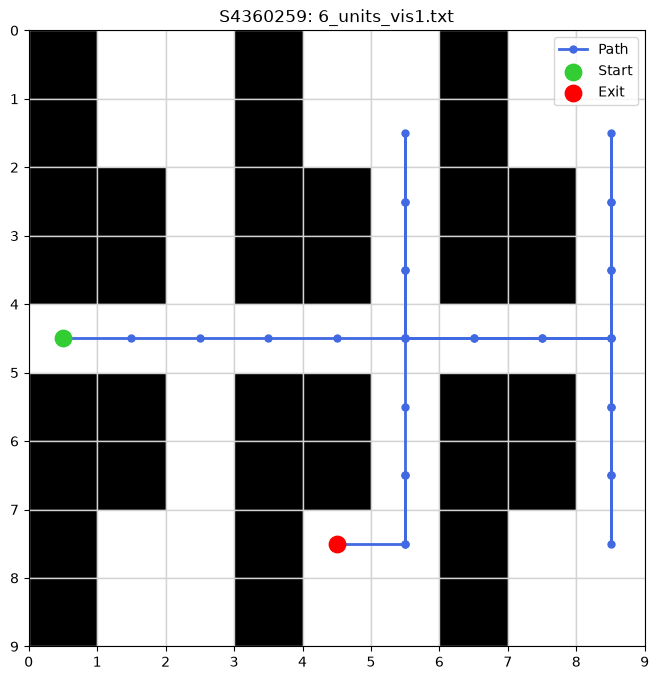

In [9]:
SUBJECT_ID = "S4360259"
MAP_NAME = "6_units_vis1.txt"

selected = next(row for row in subject_data if row["subject_id"] == SUBJECT_ID and row["map_name"] == MAP_NAME)
path = json.loads(selected["moves_taken"])

possible_maps = [
    DATA_FOLDER / "webfile/maps" / MAP_NAME,
    DATA_FOLDER / "webfile/practice" / MAP_NAME
]
map_file = next(file for file in possible_maps if file.exists())

with map_file.open() as file:
    width = int(file.readline())
    height = int(file.readline())
    maze = [list(map(int, file.readline().strip())) for _ in range(height)]

fig, ax = plt.subplots(figsize=(8, 8))

for y, row in enumerate(maze):
    for x, cell in enumerate(row[:width]):
        colour = "black" if cell == 3 else "white"
        ax.add_patch(Rectangle((x, y), 1, 1, facecolor=colour, edgecolor="lightgray"))

x_values = [point[0] + 0.5 for point in path]
y_values = [point[1] + 0.5 for point in path]

ax.plot(x_values, y_values, color="royalblue", marker="o", linewidth=2, markersize=5, label="Path")
ax.scatter(x_values[0], y_values[0], color="limegreen", s=140, zorder=3, label="Start")
ax.scatter(x_values[-1], y_values[-1], color="red", s=140, zorder=3, label="Exit")

ax.set_xlim(0, width)
ax.set_ylim(height, 0)
ax.set_aspect("equal")
ax.set_xticks(range(width + 1))
ax.set_yticks(range(height + 1))
ax.set_title(f"{SUBJECT_ID}: {MAP_NAME}")
ax.legend()
plt.show()